# Análise Exploratória da Inadimplência em Clientes de Cartão de Crédito

## Objetivo

Este projeto busca responder à seguinte pergunta:

> **Quais características e comportamentos financeiros estão mais associados à inadimplência dos clientes?**

A coluna `default` será utilizada como variável resposta:

- `0`: cliente adimplente;
- `1`: cliente inadimplente.

O projeto contém:

1. exploração dos dados;
2. transformação e limpeza;
3. visualização;
4. geração de insights;
5. conclusão e recomendações.

> **Importante:** esta é uma análise exploratória. As relações encontradas representam associações e não comprovam causalidade.


In [35]:
import sys

print(sys.executable)

c:\Users\VITU\Desktop\Projeto Inadipelcia\.venv\Scripts\python.exe


## 1. Importação das bibliotecas

In [36]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)


In [37]:
# Pasta onde os gráficos serão salvos
PASTA_GRAFICOS = Path("images")

# Cria a pasta caso ela ainda não exista
PASTA_GRAFICOS.mkdir(parents=True, exist_ok=True)

print(f"Pasta dos gráficos: {PASTA_GRAFICOS.resolve()}")

Pasta dos gráficos: C:\Users\VITU\Desktop\Projeto Inadipelcia\images


## 2. Leitura do conjunto de dados

O código abaixo procura automaticamente um arquivo CSV dentro do ambiente do Kaggle.  
Também existe uma alternativa para executar o notebook localmente.


In [38]:
# Procura arquivos CSV no Kaggle
arquivos_kaggle = list(Path("/kaggle/input").rglob("*.csv"))

if arquivos_kaggle:
    caminho_arquivo = arquivos_kaggle[0]
else:
    # Alternativa para execução local
    caminho_arquivo = Path("Python_M11_support material.csv")

print(f"Arquivo utilizado: {caminho_arquivo}")

# O texto "na" será interpretado como valor ausente
df = pd.read_csv(caminho_arquivo, na_values="na")

df.head()


Arquivo utilizado: Python_M11_support material.csv


,id,default,idade,sexo,dependentes,escolaridade,estado_civil,salario_anual,tipo_cartao,meses_de_relacionamento,qtd_produtos,iteracoes_12m,meses_inativo_12m,limite_credito,valor_transacoes_12m,qtd_transacoes_12m
0,768805383,0,45,M,3,ensino medio,casado,$60K - $80K,blue,39,5,3,1,"12.691,51","1.144,90",42
1,818770008,0,49,F,5,mestrado,solteiro,menos que $40K,blue,44,6,2,1,"8.256,96","1.291,45",33
2,713982108,0,51,M,3,mestrado,casado,$80K - $120K,blue,36,4,0,1,"3.418,56","1.887,72",20
3,769911858,0,40,F,4,ensino medio,NaN,menos que $40K,blue,34,3,1,4,"3.313,03","1.171,56",20
4,709106358,0,40,M,3,sem educacao formal,casado,$60K - $80K,blue,21,5,0,1,"4.716,22","816,08",28


In [39]:
PASTA_GRAFICOS = Path("images")
PASTA_GRAFICOS.mkdir(parents=True, exist_ok=True)

print(f"Pasta dos gráficos: {PASTA_GRAFICOS.resolve()}")

Pasta dos gráficos: C:\Users\VITU\Desktop\Projeto Inadipelcia\images


## 3. Exploração inicial

In [40]:
print(f"Quantidade de linhas: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")

df.info()


Quantidade de linhas: 10127
Quantidade de colunas: 16
Linhas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   id                       10127 non-null  int64
 1   default                  10127 non-null  int64
 2   idade                    10127 non-null  int64
 3   sexo                     10127 non-null  str  
 4   dependentes              10127 non-null  int64
 5   escolaridade             8608 non-null   str  
 6   estado_civil             9378 non-null   str  
 7   salario_anual            9015 non-null   str  
 8   tipo_cartao              10127 non-null  str  
 9   meses_de_relacionamento  10127 non-null  int64
 10  qtd_produtos             10127 non-null  int64
 11  iteracoes_12m            10127 non-null  int64
 12  meses_inativo_12m        10127 non-null  int64
 13  limite_credito           10127 non-null  s

In [41]:
# Amostra aleatória dos dados
df.sample(5, random_state=42)


,id,default,idade,sexo,dependentes,escolaridade,estado_civil,salario_anual,tipo_cartao,meses_de_relacionamento,qtd_produtos,iteracoes_12m,meses_inativo_12m,limite_credito,valor_transacoes_12m,qtd_transacoes_12m
3781,719455083,0,48,F,3,sem educacao formal,solteiro,menos que $40K,blue,39,4,4,3,"2.991,58","3.734,23",64
2922,773503308,0,59,M,1,sem educacao formal,solteiro,menos que $40K,blue,53,5,4,5,"2.192,58","4.010,67",79
5070,715452408,0,37,F,2,mestrado,divorciado,menos que $40K,blue,36,4,3,3,"1.734,09","4.727,66",67
7246,711264033,0,47,M,3,doutorado,divorciado,$40K - $60K,blue,36,4,3,2,"4.786,19","4.973,29",74
623,718943508,0,42,M,3,NaN,solteiro,$80K - $120K,blue,33,3,2,3,"3.714,31","1.454,58",35


### 3.1 Distribuição da variável `default`

In [42]:
distribuicao_default = (
    df["default"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Adimplente", 1: "Inadimplente"})
)

percentuais_default = (
    df["default"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .rename(index={0: "Adimplente", 1: "Inadimplente"})
)

resumo_default = pd.DataFrame({
    "quantidade": distribuicao_default,
    "percentual": percentuais_default.round(2)
})

resumo_default


,quantidade,percentual
default,,
Adimplente,8500,83.93
Inadimplente,1627,16.07


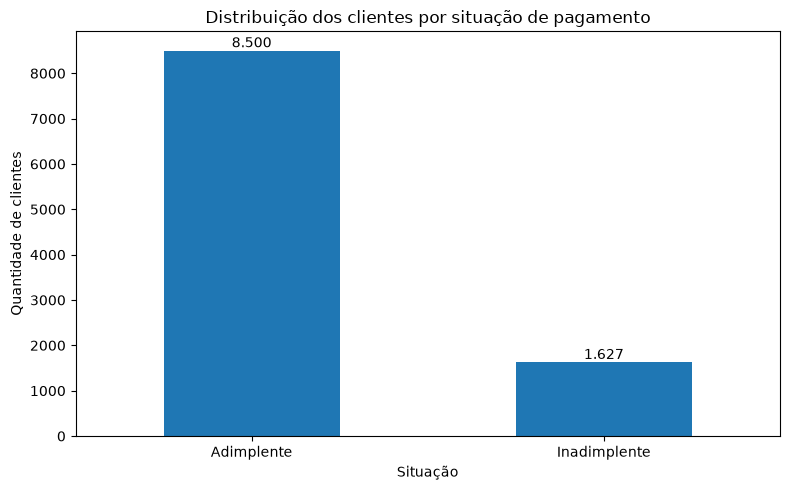

In [43]:
ax = resumo_default["quantidade"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Distribuição dos clientes por situação de pagamento"
)

ax.set_xlabel("Situação")
ax.set_ylabel("Quantidade de clientes")
ax.tick_params(axis="x", rotation=0)

for indice, valor in enumerate(resumo_default["quantidade"]):
    ax.text(indice, valor, f"{valor:,}".replace(",", "."), ha="center", va="bottom")

plt.tight_layout()
plt.savefig(
    PASTA_GRAFICOS / "01_distribuicao_clientes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


**Leitura inicial:** a base possui mais clientes adimplentes do que inadimplentes.  
Esse desequilíbrio deve ser considerado ao interpretar percentuais e comparações.


### 3.2 Tipos das colunas

In [44]:
df.dtypes.to_frame(name="tipo")


,tipo
id,int64
default,int64
idade,int64
sexo,str
dependentes,int64
escolaridade,str
estado_civil,str
salario_anual,str
tipo_cartao,str
meses_de_relacionamento,int64


As colunas `limite_credito` e `valor_transacoes_12m` representam valores monetários, mas foram lidas como texto.  
Isso acontece porque os valores utilizam ponto como separador de milhar e vírgula como separador decimal.


### 3.3 Dados ausentes

In [45]:
dados_ausentes = pd.DataFrame({
    "quantidade": df.isna().sum(),
    "percentual": (df.isna().mean() * 100).round(2)
})

dados_ausentes = dados_ausentes[dados_ausentes["quantidade"] > 0]
dados_ausentes


,quantidade,percentual
escolaridade,1519,15.00
estado_civil,749,7.40
salario_anual,1112,10.98


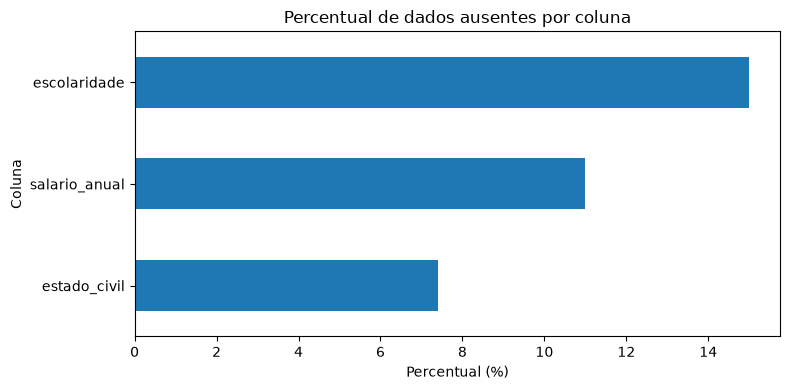

In [46]:
if not dados_ausentes.empty:
    ax = dados_ausentes["percentual"].sort_values().plot(
        kind="barh",
        figsize=(8, 4),
        title="Percentual de dados ausentes por coluna"
    )
    ax.set_xlabel("Percentual (%)")
    ax.set_ylabel("Coluna")
    plt.tight_layout()
    plt.savefig(
    PASTA_GRAFICOS / "02_dados_ausentes.png",
    dpi=300,
    bbox_inches="tight"
)
    plt.show()


## 4. Transformação e limpeza dos dados

### 4.1 Conversão das colunas monetárias

In [47]:
def converter_valor_monetario(valor):
    """Converte texto no formato brasileiro para número decimal."""
    if pd.isna(valor):
        return np.nan

    return float(
        str(valor)
        .replace(".", "")
        .replace(",", ".")
    )


colunas_monetarias = ["limite_credito", "valor_transacoes_12m"]

for coluna in colunas_monetarias:
    df[coluna] = df[coluna].apply(converter_valor_monetario)

df[colunas_monetarias].head()


,limite_credito,valor_transacoes_12m
0,12691.51,1144.90
1,8256.96,1291.45
2,3418.56,1887.72
3,3313.03,1171.56
4,4716.22,816.08


In [48]:
df[colunas_monetarias].dtypes


limite_credito          float64
valor_transacoes_12m    float64
dtype: object

### 4.2 Tratamento dos dados ausentes

Durante a exploração inicial, foram identificados valores ausentes nas variáveis `escolaridade`, `estado_civil` e `salario_anual`.

Inicialmente, foi avaliada a exclusão dos registros incompletos com o método `dropna()`. Entretanto, essa abordagem eliminaria 30,08% da base, reduzindo o número de clientes de 10.127 para 7.081.

Uma análise adicional mostrou que os clientes com informações ausentes apresentavam taxas de inadimplência ligeiramente superiores às dos clientes com informações preenchidas.

Por esse motivo, optou-se por preservar os registros e substituir os valores ausentes dessas variáveis categóricas pela categoria **"Não informado"**.

Com essa estratégia:

- Foram preservados os 10.127 registros originais.
- Nenhum cliente foi excluído.
- A taxa geral de inadimplência permaneceu em 16,07%.
- A ausência de informação passou a ser representada explicitamente.

Essa decisão evita a perda de registros, mas não elimina possíveis vieses relacionados à ausência dos dados. As associações identificadas são exploratórias e não demonstram causalidade.


In [49]:
linhas_antes = len(df)
taxa_antes = df["default"].mean() * 100


# Criar uma cópia da base original
df_limpo = df.copy()

# Preservar registros com informações categóricas ausentes
colunas_categoricas = [
    "escolaridade",
    "estado_civil",
    "salario_anual"
]

df_limpo[colunas_categoricas] = (
    df_limpo[colunas_categoricas].fillna("Não informado")
)


linhas_depois = len(df_limpo)
taxa_depois = df_limpo["default"].mean() * 100

print(f"Linhas antes da limpeza: {linhas_antes}")
print(f"Linhas depois da limpeza: {linhas_depois}")
print(f"Linhas removidas: {linhas_antes - linhas_depois}")
print(f"Percentual removido: {(linhas_antes - linhas_depois) / linhas_antes * 100:.2f}%")
print()
print(f"Taxa de inadimplência antes: {taxa_antes:.2f}%")
print(f"Taxa de inadimplência depois: {taxa_depois:.2f}%")


Linhas antes da limpeza: 10127
Linhas depois da limpeza: 10127
Linhas removidas: 0
Percentual removido: 0.00%

Taxa de inadimplência antes: 16.07%
Taxa de inadimplência depois: 16.07%


In [50]:

# Criar uma cópia para testar o novo tratamento
df_teste = df.copy()

# Colunas com dados ausentes
colunas = ["escolaridade", "estado_civil", "salario_anual"]

# Substituir valores ausentes por "Não informado"
df_teste[colunas] = df_teste[colunas].fillna("Não informado")

# Verificar o resultado
print("Registros preservados:", len(df_teste))
print("Valores ausentes restantes:")
print(df_teste.isna().sum())


Registros preservados: 10127
Valores ausentes restantes:
id                         0
default                    0
idade                      0
sexo                       0
dependentes                0
escolaridade               0
estado_civil               0
salario_anual              0
tipo_cartao                0
meses_de_relacionamento    0
qtd_produtos               0
iteracoes_12m              0
meses_inativo_12m          0
limite_credito             0
valor_transacoes_12m       0
qtd_transacoes_12m         0
dtype: int64


In [51]:
print(f"Valores ausentes restantes: {df_limpo.isna().sum().sum()}")
print(f"Linhas duplicadas restantes: {df_limpo.duplicated().sum()}")


Valores ausentes restantes: 0
Linhas duplicadas restantes: 0


In [52]:

# Comparação entre as estratégias de tratamento

taxa_original = df["default"].mean() * 100
taxa_exclusao = df_limpo["default"].mean() * 100
taxa_preenchimento = df_teste["default"].mean() * 100

print(f"Taxa original: {taxa_original:.2f}%")
print(f"Taxa com exclusão: {taxa_exclusao:.2f}%")
print(f"Taxa com preenchimento: {taxa_preenchimento:.2f}%")


Taxa original: 16.07%
Taxa com exclusão: 16.07%
Taxa com preenchimento: 16.07%


In [53]:

# Investigar a relação entre dados ausentes e inadimplência

colunas = ["escolaridade", "estado_civil", "salario_anual"]

for coluna in colunas:
    print(f"\nColuna: {coluna}")

    resultado = (
        df.groupby(df[coluna].isna())["default"]
        .agg(["count", "mean"])
    )

    resultado["mean"] = (resultado["mean"] * 100).round(2)

    resultado.index = resultado.index.map({
        False: "Informado",
        True: "Não informado"
    })

    resultado = resultado.rename(columns={
        "count": "Clientes",
        "mean": "Inadimplência (%)"
    })

    print(resultado)



Coluna: escolaridade
               Clientes  Inadimplência (%)
escolaridade                              
Informado          8608              15.93
Não informado      1519              16.85

Coluna: estado_civil
               Clientes  Inadimplência (%)
estado_civil                              
Informado          9378              15.97
Não informado       749              17.22

Coluna: salario_anual
               Clientes  Inadimplência (%)
salario_anual                             
Informado          9015              15.97
Não informado      1112              16.82


## 5. Análise exploratória e visualização

### 5.1 Comparação das médias entre adimplentes e inadimplentes

In [54]:
colunas_numericas = [
    "idade",
    "dependentes",
    "meses_de_relacionamento",
    "qtd_produtos",
    "iteracoes_12m",
    "meses_inativo_12m",
    "limite_credito",
    "valor_transacoes_12m",
    "qtd_transacoes_12m"
]

comparacao_medias = (
    df_limpo
    .groupby("default")[colunas_numericas]
    .mean()
    .transpose()
    .rename(columns={0: "Adimplentes", 1: "Inadimplentes"})
)

comparacao_medias["diferença_percentual"] = (
    (comparacao_medias["Inadimplentes"] - comparacao_medias["Adimplentes"])
    / comparacao_medias["Adimplentes"]
    * 100
)

comparacao_medias.round(2)


default,Adimplentes,Inadimplentes,diferença_percentual
idade,46.26,46.66,0.86
dependentes,2.34,2.40,2.88
meses_de_relacionamento,35.88,36.18,0.83
qtd_produtos,3.91,3.28,-16.22
iteracoes_12m,2.36,2.97,26.14
meses_inativo_12m,2.27,2.69,18.45
limite_credito,8727.37,8136.52,-6.77
valor_transacoes_12m,4655.15,3095.52,-33.50
qtd_transacoes_12m,68.67,44.93,-34.57


### 5.2 Quantidade de transações nos últimos 12 meses

In [55]:
print("Jupyter funcionando!")

Jupyter funcionando!


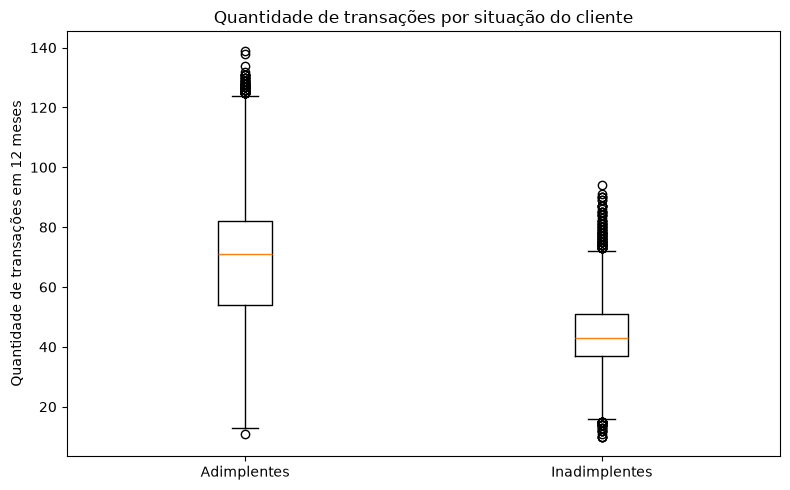

In [ ]:
dados_boxplot = [
    df_limpo.loc[df_limpo["default"] == 0, "qtd_transacoes_12m"],
    df_limpo.loc[df_limpo["default"] == 1, "qtd_transacoes_12m"]
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    dados_boxplot,
    tick_labels=["Adimplentes", "Inadimplentes"]
)

plt.title("Quantidade de transações por situação do cliente")
plt.ylabel("Quantidade de transações em 12 meses")

plt.tight_layout()


plt.tight_layout()

# Salvar o gráfico atualizado
plt.savefig(
    "images/03_quantidade_transacoes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Insight:** clientes inadimplentes apresentam, em média, uma quantidade menor de transações.  
Isso indica que a redução da movimentação do cartão pode ser um sinal relevante de risco.


### 5.3 Valor total transacionado nos últimos 12 meses

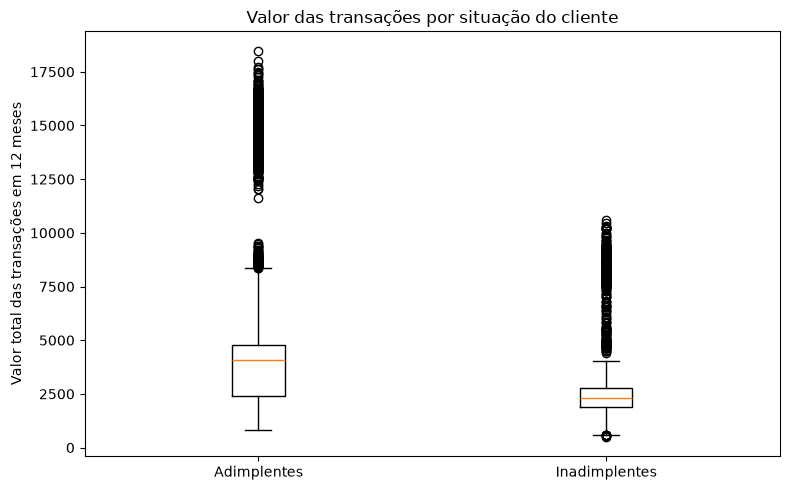

In [57]:
dados_boxplot = [
    df_limpo.loc[df_limpo["default"] == 0, "valor_transacoes_12m"],
    df_limpo.loc[df_limpo["default"] == 1, "valor_transacoes_12m"]
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    dados_boxplot,
    tick_labels=["Adimplentes", "Inadimplentes"]
)

plt.title("Valor das transações por situação do cliente")
plt.ylabel("Valor total das transações em 12 meses")

plt.tight_layout()

plt.savefig(
    PASTA_GRAFICOS / "04_valor_transacoes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Insight:** o grupo inadimplente movimenta menos dinheiro no cartão.  
A combinação entre poucas transações e baixo valor movimentado reforça a hipótese de menor engajamento financeiro.


### 5.4 Quantidade de produtos contratados

In [58]:
taxa_produtos = (
    df_limpo
    .groupby("qtd_produtos")["default"]
    .mean()
    .mul(100)
)



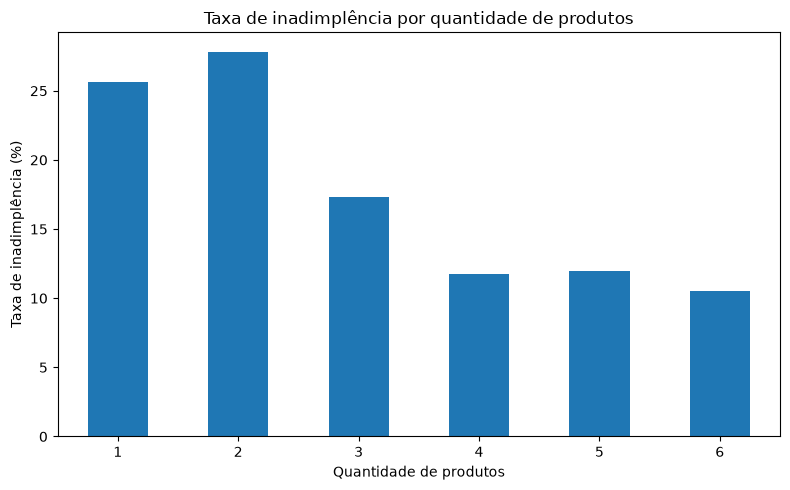

In [59]:
ax = taxa_produtos.plot(
    kind="bar",
    figsize=(8, 5),
    title="Taxa de inadimplência por quantidade de produtos"
)

ax.set_xlabel("Quantidade de produtos")
ax.set_ylabel("Taxa de inadimplência (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.savefig(
    PASTA_GRAFICOS / "05_taxa_por_produtos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Insight:** clientes com poucos produtos contratados apresentam uma taxa maior de inadimplência.  
Uma relação mais ampla com a instituição pode estar associada a maior permanência e regularidade.


### 5.5 Interações com o cliente nos últimos 12 meses

In [60]:
taxa_interacoes = (
    df_limpo
    .groupby("iteracoes_12m")["default"]
    .mean()
    .mul(100)
)


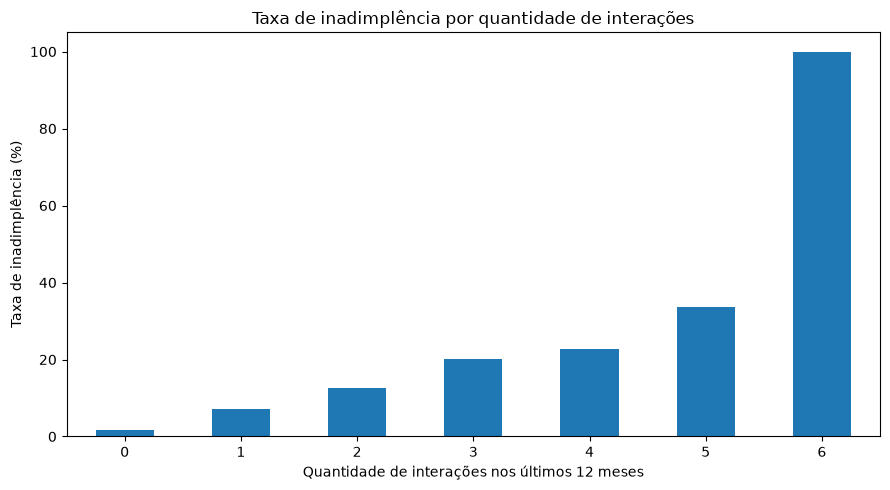

In [61]:
ax = taxa_interacoes.plot(
    kind="bar",
    figsize=(9, 5),
    title="Taxa de inadimplência por quantidade de interações"
)

ax.set_xlabel("Quantidade de interações nos últimos 12 meses")
ax.set_ylabel("Taxa de inadimplência (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.savefig(
    PASTA_GRAFICOS / "06_taxa_por_interacoes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Insight:** a taxa de inadimplência aumenta entre clientes com mais interações registradas.  
Uma interpretação possível é que parte dessas interações esteja ligada a problemas, cobranças ou tentativas de atendimento.  
O conjunto de dados, porém, não informa o motivo das interações.


### 5.6 Meses de inatividade

In [62]:
taxa_inatividade = (
    df_limpo
    .groupby("meses_inativo_12m")["default"]
    .mean()
    .mul(100)
)



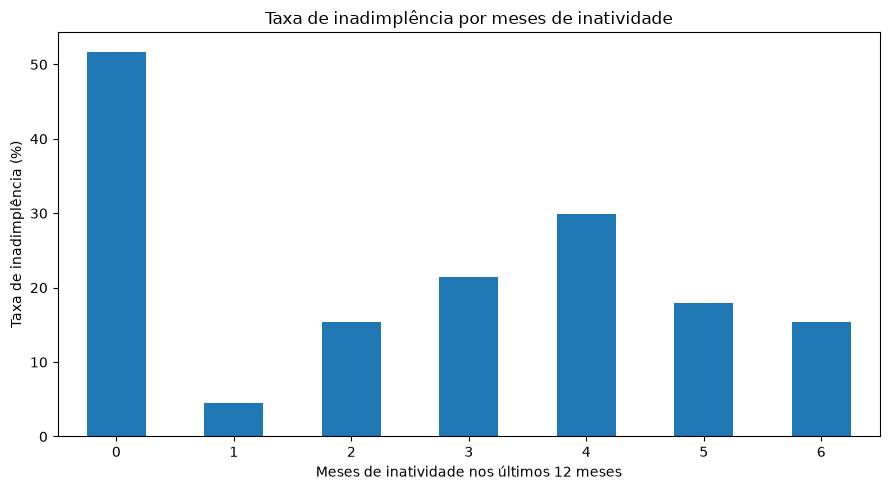

In [63]:
ax = taxa_inatividade.plot(
    kind="bar",
    figsize=(9, 5),
    title="Taxa de inadimplência por meses de inatividade"
)

ax.set_xlabel("Meses de inatividade nos últimos 12 meses")
ax.set_ylabel("Taxa de inadimplência (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.savefig(
    PASTA_GRAFICOS / "07_taxa_por_inatividade.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Insight:** em boa parte da distribuição, mais meses de inatividade estão associados a uma taxa maior de inadimplência.  
Algumas categorias possuem poucas observações e devem ser interpretadas com cautela.


### 5.7 Variáveis categóricas

In [64]:
def plotar_taxa_categoria(
    dataframe,
    coluna,
    titulo,
    nome_arquivo
):
    tabela = (
        dataframe
        .groupby(coluna)["default"]
        .agg(
            quantidade="size",
            taxa_inadimplencia="mean"
        )
        .sort_values(
            "taxa_inadimplencia",
            ascending=False
        )
    )

    tabela["taxa_inadimplencia"] *= 100

    ax = tabela["taxa_inadimplencia"].plot(
        kind="bar",
        figsize=(10, 5),
        title=titulo
    )

    ax.set_xlabel(
        coluna.replace("_", " ").title()
    )
    ax.set_ylabel("Taxa de inadimplência (%)")
    ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()

    plt.savefig(
        PASTA_GRAFICOS / nome_arquivo,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    return tabela.round(2)

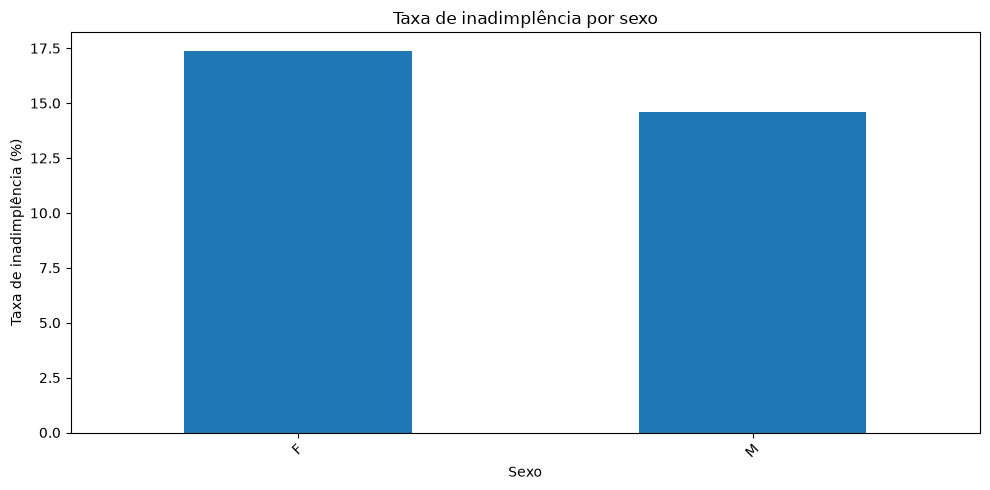

,quantidade,taxa_inadimplencia
sexo,,
F,5358,17.36
M,4769,14.62


In [65]:
tabela_sexo = plotar_taxa_categoria(
    dataframe=df_limpo,
    coluna="sexo",
    titulo="Taxa de inadimplência por sexo",
    nome_arquivo="08_taxa_por_sexo.png"
)

tabela_sexo


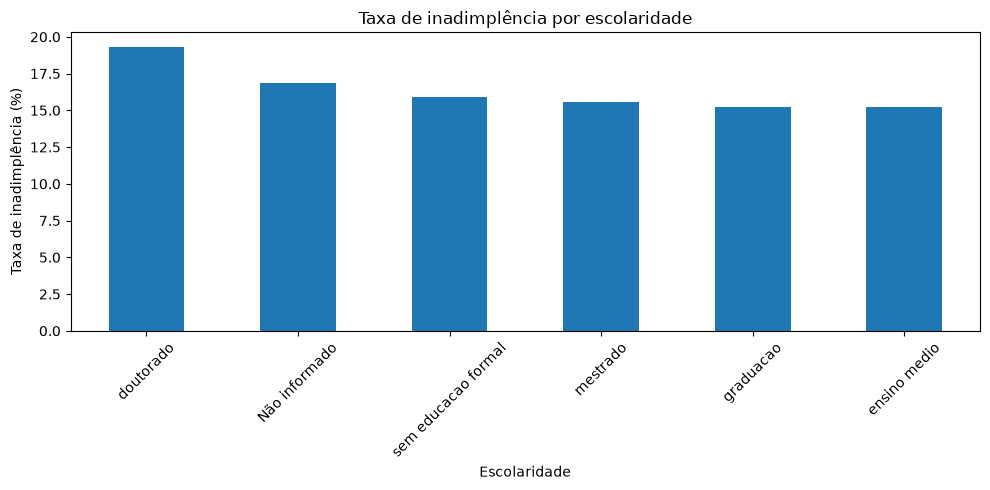

,quantidade,taxa_inadimplencia
escolaridade,,
doutorado,967,19.34
Não informado,1519,16.85
sem educacao formal,1487,15.94
mestrado,3128,15.57
graduacao,1013,15.20
ensino medio,2013,15.20


In [66]:
tabela_escolaridade = plotar_taxa_categoria(
    dataframe=df_limpo,
    coluna="escolaridade",
    titulo="Taxa de inadimplência por escolaridade",
    nome_arquivo="09_taxa_por_escolaridade.png"
)

tabela_escolaridade


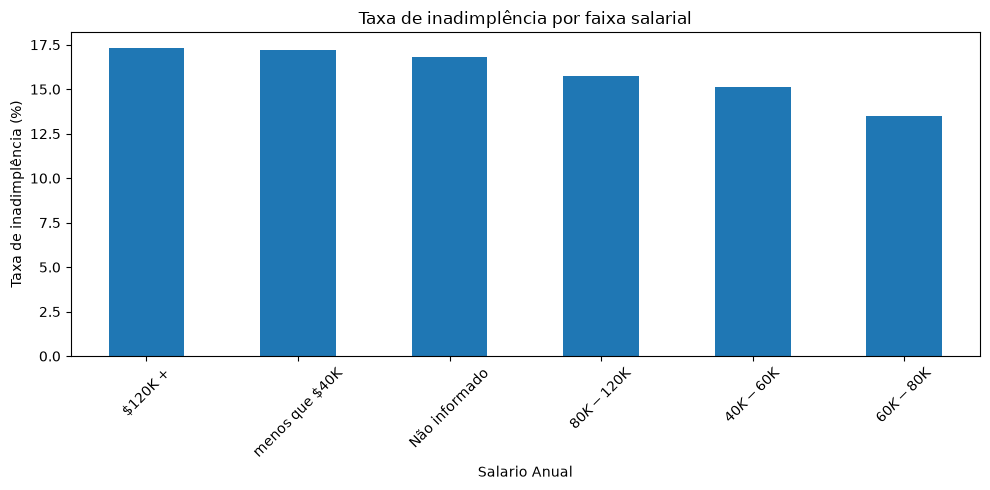

,quantidade,taxa_inadimplencia
salario_anual,,
$120K +,727,17.33
menos que $40K,3561,17.19
Não informado,1112,16.82
$80K - $120K,1535,15.77
$40K - $60K,1790,15.14
$60K - $80K,1402,13.48


In [67]:
tabela_salario = plotar_taxa_categoria(
    dataframe=df_limpo,
    coluna="salario_anual",
    titulo="Taxa de inadimplência por faixa salarial",
    nome_arquivo="10_taxa_por_salario.png"
)

tabela_salario

As diferenças entre algumas categorias são pequenas ou possuem amostras desiguais.  
Por isso, características demográficas isoladas parecem menos úteis do que indicadores de comportamento financeiro.


### 5.8 Matriz de correlação

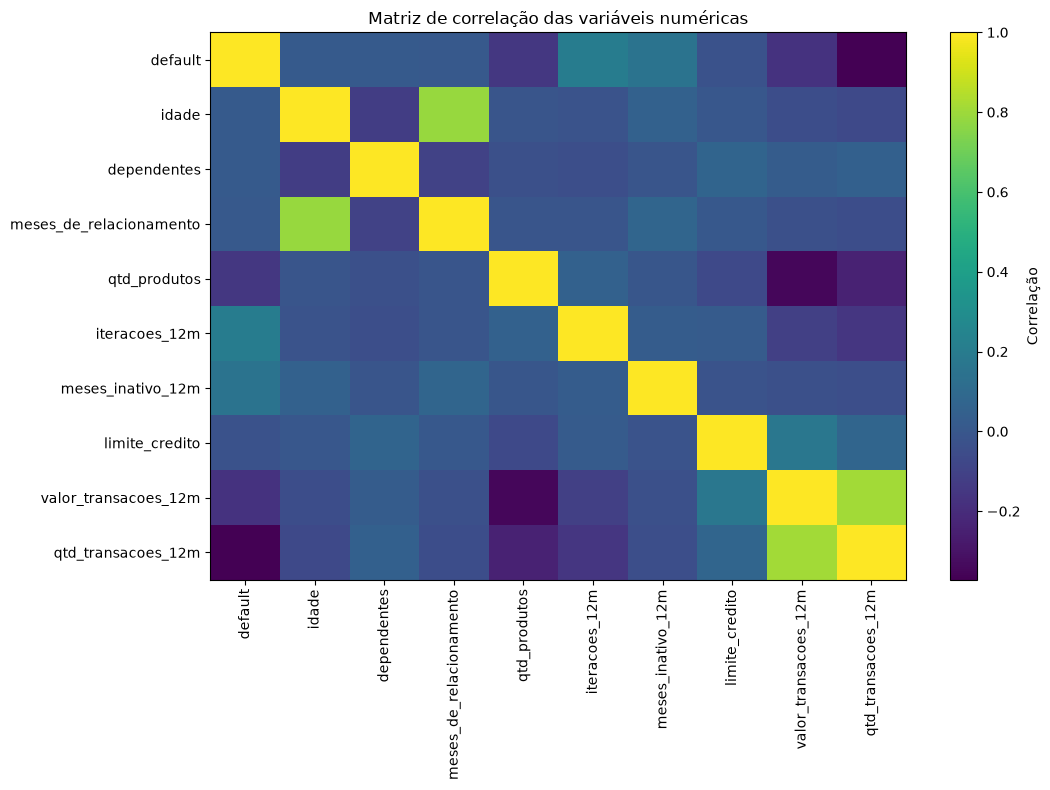

In [68]:
correlacao = (
    df_limpo
    .drop(columns="id")
    .select_dtypes(include="number")
    .corr()
)

fig, ax = plt.subplots(figsize=(11, 8))
imagem = ax.imshow(correlacao, aspect="auto")

ax.set_xticks(range(len(correlacao.columns)))
ax.set_xticklabels(correlacao.columns, rotation=90)

ax.set_yticks(range(len(correlacao.index)))
ax.set_yticklabels(correlacao.index)

fig.colorbar(imagem, ax=ax, label="Correlação")
ax.set_title("Matriz de correlação das variáveis numéricas")

plt.tight_layout()
fig.savefig(
    PASTA_GRAFICOS / "11_matriz_correlacao.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 6. Storytelling: o que os dados contam?

A análise mostra que a inadimplência está mais associada ao **comportamento de uso do cartão** do que às características demográficas.

Os clientes inadimplentes apresentam, em média:

- menos produtos contratados;
- menor quantidade de transações;
- menor valor total movimentado;
- mais meses de inatividade;
- maior quantidade de interações registradas com a instituição.

Esses resultados sugerem um possível processo de afastamento: o cliente passa a utilizar menos o cartão, movimenta menos dinheiro, permanece inativo por mais tempo e registra mais interações com a instituição.

Características como idade, tempo de relacionamento e limite de crédito apresentam diferenças menores entre os grupos e, isoladamente, parecem menos decisivas.


## 7. Conclusões e recomendações

A análise exploratória foi realizada com 10.127 registros de clientes de cartão de crédito, preservados após o tratamento dos valores ausentes nas variáveis categóricas.

A taxa geral de inadimplência observada foi de 16,07%.

### Principais resultados

Em comparação com os clientes adimplentes, os inadimplentes apresentaram, em média:

- **34,57% menos transações** nos últimos 12 meses.
- **33,50% menos valor transacionado**.
- **18,45% mais meses de inatividade**.
- **16,22% menos produtos contratados**.
- **26,14% mais interações** com a instituição financeira.

Os resultados sugerem uma associação entre inadimplência e menor utilização dos serviços financeiros, além de maior inatividade e maior frequência de interações.

### Recomendações de negócio

A instituição financeira poderia investigar esses indicadores para compreender melhor o comportamento dos clientes e identificar oportunidades de acompanhamento e relacionamento.

Entre as possíveis iniciativas estão o monitoramento de mudanças no uso do cartão, a análise dos motivos de contato com a instituição e a avaliação de estratégias de relacionamento.

### Limitações

Esta análise é exploratória e identifica associações estatísticas, não relações de causa e efeito.

O preenchimento dos valores ausentes com a categoria "Não informado" preservou os registros, mas não elimina possíveis vieses.

Além disso, não foi realizada validação preditiva nem análise temporal para determinar se os indicadores antecedem a inadimplência.


In [69]:

# Comparação atualizada entre os grupos

indicadores = [
    "qtd_transacoes_12m",
    "valor_transacoes_12m",
    "meses_inativo_12m",
    "qtd_produtos",
    "iteracoes_12m"
]

resumo_final = (
    df_limpo
    .groupby("default")[indicadores]
    .mean()
    .T
)

resumo_final.columns = [
    "Adimplentes",
    "Inadimplentes"
]

resumo_final["Diferença (%)"] = (
    (resumo_final["Inadimplentes"] /
     resumo_final["Adimplentes"] - 1) * 100
).round(2)

print("Comparação final com 10.127 clientes:")
display(resumo_final.round(2))


Comparação final com 10.127 clientes:


,Adimplentes,Inadimplentes,Diferença (%)
qtd_transacoes_12m,68.67,44.93,-34.57
valor_transacoes_12m,4655.15,3095.52,-33.50
meses_inativo_12m,2.27,2.69,18.45
qtd_produtos,3.91,3.28,-16.22
iteracoes_12m,2.36,2.97,26.14


## 8. Checklist antes da publicação no Kaggle

- [ ] Executar todas as células sem erro;
- [ ] conferir se todos os gráficos aparecem;
- [ ] revisar título, textos e conclusões;
- [ ] acrescentar seu nome na introdução;
- [ ] salvar uma versão completa;
- [ ] deixar o notebook público;
- [ ] copiar o link e enviar para a tutoria.
